# Asset-liability matching on real bond data
Same formulation as `alm.ipynb`, with a WRDS bond universe.

Snapshot: **2025-11-30** (`bondret`) and **2025-11-28** (CRSP Treasuries). WRDS corporate data is complete through Nov 2025 and thins out after that, so this is the latest usable cross-section.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from alm import assets, data, liabilities, optimize

BONDRET_DATE, TSY_DATE = "2025-11-30", "2025-11-28"

## Data
Pulled once, then read from `data/` (gitignored).

In [2]:
corp_raw = data.cached(data.DATA_DIR / f"bondret_{BONDRET_DATE}.csv", lambda: data.pull_bondret(data.connect(), BONDRET_DATE))
tsy_raw = data.cached(data.DATA_DIR / f"treasuries_{TSY_DATE}.csv", lambda: data.pull_treasuries(data.connect(), TSY_DATE))
u = assets.build_universe(corp_raw, tsy_raw, asof=TSY_DATE)
y = assets.net_yield(u)
k = assets.capital_factor(u)
print(len(u), "bonds,", u.issuer.nunique(), "issuers")
u.assign(net_yield=y).groupby("rating").agg(n=("name", "size"), ytm=("ytm", "mean"), net_yield=("net_yield", "mean"), mod_dur=("mod_dur", "mean")).round(4)

7282 bonds, 800 issuers


,n,ytm,net_yield,mod_dur
rating,,,,
A,2877,0.0466,0.0445,7.5053
AA,391,0.0451,0.0441,7.9737
AAA,64,0.0451,0.0446,9.3252
BBB,3652,0.0489,0.0445,6.4561
UST,298,0.0387,0.0387,6.6150


Treasury curve, and corporate yields against it.

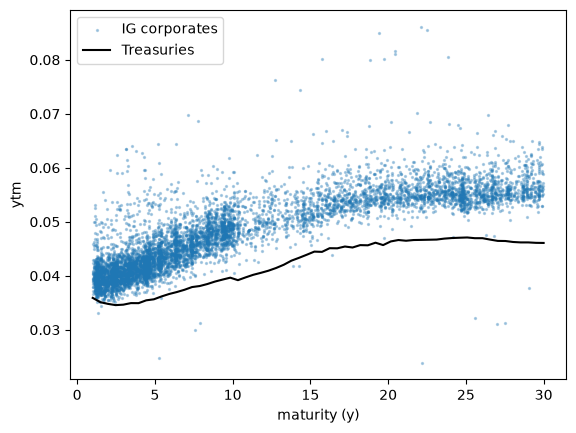

In [3]:
curve = assets.curve(u)
c = u[u.rating != "UST"]
plt.scatter(c.maturity, c.ytm, s=2, alpha=0.3, label="IG corporates")
m = np.linspace(1, 30, 60)
plt.plot(m, curve(m), color="k", label="Treasuries")
plt.xlabel("maturity (y)"); plt.ylabel("ytm"); plt.legend(); plt.show()

## Liabilities
Same block as the synthetic notebook, discounted on the Treasury curve (flat at the curve yield near the liability duration).

In [4]:
T = 40
qx = liabilities.gompertz_qx()
ages = np.random.default_rng(0).integers(65, 76, size=1000)
L = liabilities.annuity_cashflows(qx, ages, payment=0.01, horizon=T)

rate = 0.04
for _ in range(3):
    pv, D_L = liabilities.pv_duration(L, rate)
    rate = float(curve(D_L))
print(f"discount rate {rate:.4f}, PV {pv:.1f}m, modified duration {D_L:.2f}")
C = assets.cashflow_matrix(u, T)

discount rate 0.0387, PV 108.1m, modified duration 8.58


## Deterministic LP
Issuer cap is per issuer (Treasuries uncapped). Reinvestment rate is the 1y Treasury yield.

In [5]:
A = 1.02 * pv
limits = dict(r=float(curve(1.0)), delta=0.5, max_weight=0.03, rating_caps={"BBB": 0.25}, capital_cap=0.015 * A)

def solve(**kw):
    args = dict(y=y.to_numpy(), price=u.price.to_numpy(), C=C, L=L, dur=u.mod_dur.to_numpy(),
                D_L=D_L, A=A, k=k.to_numpy(), rating=u.rating.to_numpy(), issuer=u.issuer.to_numpy(), **limits)
    args.update(kw)
    return optimize.solve_deterministic(**args)

res = solve()
print(res.status, f"net yield {res.net_yield:.4f}")
pd.Series(res.duals, name="income per $ of slack").round(4)

optimal net yield 0.0536


budget           0.0466
cash_matching   -0.0544
duration_hi      0.0007
duration_lo      0.0000
issuer           0.0871
capital          0.5416
rating_BBB       0.0000
Name: income per $ of slack, dtype: float64

In [6]:
step = 1e-4 * A
res2 = solve(capital_cap=limits["capital_cap"] + step)
print(f"predicted {res.duals['capital'] * step:.5f}, actual {(res2.net_yield - res.net_yield) * A:.5f}")

predicted 0.00597, actual 0.00597


Portfolio by rating and maturity bucket, as share of A.

In [7]:
w = pd.Series(res.x * u.price.to_numpy() / A, index=u.index)
bucket = pd.cut(u.maturity, [0, 2, 5, 10, 20, 30])
print(f"bonds held: {(w > 1e-6).sum()}")
w.groupby([u.rating, bucket], observed=True).sum().unstack().round(3)

bonds held: 36


maturity,"(0, 2]","(2, 5]","(5, 10]","(10, 20]","(20, 30]"
rating,,,,,
A,0.000,0.03,0.033,0.030,0.090
AA,0.000,0.00,0.000,0.109,0.210
AAA,0.000,0.00,0.000,0.060,0.129
BBB,0.000,0.06,0.060,0.000,0.060
UST,0.129,0.00,0.000,0.000,0.000


## Stochastic LP
Two independent system-wide shocks per scenario: a mortality multiplier (lognormal, median 1, sigma 0.15) and a reinvestment rate path (parallel shift and tilt, sd 1% each). Shortfalls are borrowed at the scenario rate plus 3%. `iota` is the price of a shortfall: the objective is net income minus iota times the average borrowed balance. Fit on 200 scenarios, judged on 1,000 fresh ones.

In [8]:
from alm import scenarios

KAPPA, SIGMA = 0.03, 0.15
r0 = limits["r"]

def draw(n, seed):
    f = scenarios.longevity_scenarios(n, SIGMA, seed)
    return liabilities.scenario_cashflows(qx, ages, 0.01, T, f), scenarios.rate_scenarios(r0, n, T, seed=seed + 1000)

L_fit, r_fit = draw(200, 1)
L_test, r_test = draw(1000, 2)
price, income = u.price.to_numpy(), y.to_numpy() * u.price.to_numpy()

def judge(x, name):
    peak = optimize.simulate(x, price, C, L_test, r_test, A, KAPPA).max(axis=1)
    worst = np.sort(peak)[::-1][:int(0.05 * len(peak))]
    return dict(name=name, income=income @ x / A, p_shortfall=(peak > 1e-6).mean(), mean_peak=peak.mean(), cvar95_peak=worst.mean())

rows, sto = [judge(res.x, "deterministic")], {}
for iota in [0.0, 0.02, 0.05, 0.1, 0.3, 1.0, 3.0]:
    sto[iota] = optimize.solve_stochastic(
        y=y.to_numpy(), price=price, C=C, L_scen=L_fit, r_scen=r_fit, dur=u.mod_dur.to_numpy(), D_L=D_L, A=A, k=k.to_numpy(),
        kappa=KAPPA, iota=iota, delta=limits["delta"], max_weight=limits["max_weight"], rating=u.rating.to_numpy(),
        rating_caps=limits["rating_caps"], capital_cap=limits["capital_cap"], issuer=u.issuer.to_numpy())
    rows.append(judge(sto[iota].x, f"stochastic iota={iota}"))
compare = pd.DataFrame(rows).set_index("name")
compare.round(4)

,income,p_shortfall,mean_peak,cvar95_peak
name,,,,
deterministic,0.0536,0.554,3.5572,17.0761
stochastic iota=0.0,0.0538,0.982,13.1394,23.3941
stochastic iota=0.02,0.0537,0.961,6.1418,12.9324
stochastic iota=0.05,0.0536,0.698,2.4855,11.4065
stochastic iota=0.1,0.0535,0.530,1.4025,8.3723
stochastic iota=0.3,0.0534,0.251,0.4458,4.5735
stochastic iota=1.0,0.0532,0.075,0.0978,1.7902
stochastic iota=3.0,0.0530,0.020,0.0180,0.3597


Shortfall columns are the peak amount borrowed in a scenario, in $m, against $110m of assets. p_shortfall is the share of test scenarios with any shortfall.

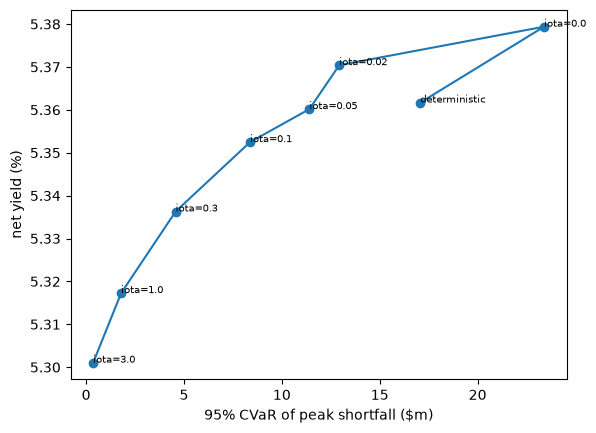

In [9]:
plt.plot(compare.cvar95_peak, compare.income * 100, "o-")
for name, row in compare.iterrows():
    plt.annotate(name.replace("stochastic ", ""), (row.cvar95_peak, row.income * 100), fontsize=7)
plt.xlabel("95% CVaR of peak shortfall ($m)"); plt.ylabel("net yield (%)"); plt.show()

## Diagnostics
Does the duration match? Does the cash flow match? Are the positions tradeable?

In [10]:
pick = {"deterministic": res.x, "stochastic iota=1": sto[1.0].x}
print(f"liability modified duration {D_L:.2f}, allowed gap +-{limits['delta']}")
for name, x in pick.items():
    mv = price * x
    print(f"{name}: asset duration {u.mod_dur.to_numpy() @ mv / mv.sum():.2f}, bonds held {(mv > 1e-6).sum()}")

b5 = np.arange(T) // 5
print("\nbond cash flow vs liability by 5-year bucket ($m), deterministic")
pd.DataFrame({"bond_cf": pd.Series(C @ res.x).groupby(b5).sum(), "liability": pd.Series(L).groupby(b5).sum()}).round(1).T

liability modified duration 8.58, allowed gap +-0.5
deterministic: asset duration 9.08, bonds held 36
stochastic iota=1: asset duration 8.98, bonds held 47

bond cash flow vs liability by 5-year bucket ($m), deterministic


,0,1,2,3,4,5,6,7
bond_cf,52.3,34.6,28.2,28.0,42.9,27.5,0.0,0.0
liability,46.6,39.6,30.8,21.0,11.9,5.1,1.5,0.3


In [11]:
held = res.x > 1e-6
pos = pd.DataFrame({"name": u.name[held], "rating": u.rating[held], "maturity": u.maturity[held].round(1), "par_m": res.x[held]})
print(pos.par_m.describe().round(3).to_string())
print(f"under $1m: {(pos.par_m < 1).sum()} of {len(pos)}")
ao = corp_raw.set_index("cusip").amount_outstanding / 1000
print(f"largest share of an issue held: {(pos.par_m / pos.name.map(ao)).max():.1%}")

base_r = np.full((1, T), r0)
for lot in (0.01, 0.1, 1.0):
    xr = np.round(res.x / lot) * lot
    d = optimize.simulate(xr, price, C, L[None, :], base_r, A, KAPPA)
    print(f"lot ${lot}m: cash left {A - price @ xr:.2f}m, peak shortfall {d.max():.2f}m, bonds {(xr > 0).sum()}, net yield {income @ xr / A:.4f}")

count    36.000
mean      3.361
std       2.235
min       0.070
25%       2.896
50%       3.265
75%       4.028
max      13.812
under $1m: 5 of 36
largest share of an issue held: 1.5%
lot $0.01m: cash left 0.01m, peak shortfall 0.00m, bonds 36, net yield 0.0536
lot $0.1m: cash left -0.08m, peak shortfall 0.16m, bonds 36, net yield 0.0537
lot $1.0m: cash left 1.96m, peak shortfall 0.24m, bonds 32, net yield 0.0526
